# 01 · Thin end-to-end pipeline — analysis (stage 4)

Loads the outputs of `python -m heisenbig.pipeline` (stages 1→3) from `data/processed/`
and plots them. **Nothing is recomputed here**; re-run the pipeline to refresh
(`bash scripts/run_thin_e2e.sh`).

> ⚠️ **Caveat — read before interpreting any number below.**
> This version uses **ENDF MF=3** cross sections. In the resolved resonance region (RRR) MF=3 holds only a
> *background*; the resonances themselves are stored as parameters in MF=2 and are **not reconstructed** here.
> For U-235 the MF=3 fission and capture curves are exactly **zero from 1e-5 eV to 2.24 keV**, and for U-238 capture up to ~20 keV, so
> thermal U-235 fission is missing entirely. **Absolute k_inf values are therefore not physically meaningful yet.**
> The point of this notebook is to show the plumbing works end to end; dense pointwise data (POINT2025 or ACE)
> will replace MF=3 later without changing the pipeline structure.

In [1]:
import json, os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from heisenbig.compress import PCACompressor

OUT = Path(os.environ.get("HEISENBIG_DATA", "../data")) / "processed"
run = json.loads((OUT / "run_summary.json").read_text())
grid = json.loads((OUT / "xs_wide_grid.json").read_text())
pca_err = json.loads((OUT / "pca_errors.json").read_text())
uqs = json.loads((OUT / "uq_summary.json").read_text())
E = np.array(grid["energies"])

wide = pd.read_parquet(OUT / "xs_wide")
samples = pd.read_parquet(OUT / "uq" / "samples")
model = PCACompressor.load(OUT / "models" / "pca.joblib")

s1, s2, s3 = (run["stages"][k] for k in ("1_etl", "2_grid_compress", "3_uq"))
print(f"Stage 1: {s1['files']} files ({s1['failed']} failed) -> {s1['rows']:,} long rows, "
      f"{s1['curves']} curves, {s1['nuclides']} nuclides  [{s1['seconds']} s]")
print(f"Stage 2: wide matrix {s2['matrix_shape']} on {grid['n']}-pt log grid "
      f"{grid['emin']:g}-{grid['emax']:g} eV, chosen k = {s2['chosen_k']}  [{s2['seconds']} s]")
print(f"Stage 3: k_inf nominal original = {s3['k_inf_original']:.5f}, "
      f"PCA-reconstructed = {s3['k_inf_reconstructed']:.5f}  [{s3['seconds']} s]")
print("nu-bar source:", uqs["nu_source"])
print(f"Total pipeline wall-clock: {run['total_seconds']} s")

Stage 1: 558 files (0 failed) -> 540,577 long rows, 1758 curves, 558 nuclides  [51.0 s]
Stage 2: wide matrix [1758, 2000] on 2000-pt log grid 1e-05-2e+07 eV, chosen k = 64  [26.6 s]
Stage 3: k_inf nominal original = 0.66415, PCA-reconstructed = 0.70166  [13.9 s]
nu-bar source: {'U235': 'endf MF1/MT452', 'U238': 'endf MF1/MT452'}
Total pipeline wall-clock: 91.6 s


## 1. Cross sections on the common grid
Solid = resampled ENDF MF=3 curve; dashed = PCA reconstruction at the chosen k. Zeros (e.g. the U-235/U-238 RRR gap) are not drawn on log axes.

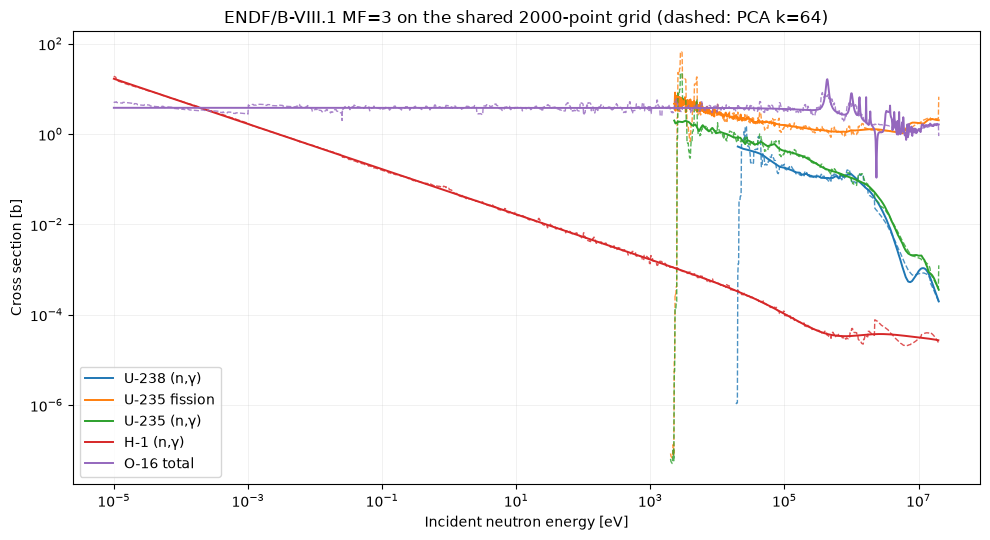

In [2]:
def row(nuc, mt):
    r = wide[(wide.nuclide == nuc) & (wide.mt == mt)]
    return np.asarray(r.iloc[0]["xs"]) if len(r) else None

picks = [("U238", 102, "U-238 (n,γ)"), ("U235", 18, "U-235 fission"), ("U235", 102, "U-235 (n,γ)"),
         ("H1", 102, "H-1 (n,γ)"), ("O16", 1, "O-16 total")]
fig, ax = plt.subplots(figsize=(10, 5.5))
for i, (nuc, mt, label) in enumerate(picks):
    x = row(nuc, mt)
    if x is None:
        continue
    rec = model.decode(model.encode(x[None]))[0]
    c = f"C{i}"
    ax.loglog(E, np.where(x > 0, x, np.nan), color=c, lw=1.4, label=label)
    ax.loglog(E, np.where(rec > 1e-8, rec, np.nan), color=c, lw=1, ls="--", alpha=.8)
ax.set(xlabel="Incident neutron energy [eV]", ylabel="Cross section [b]",
       title=f"ENDF/B-VIII.1 MF=3 on the shared {grid['n']}-point grid (dashed: PCA k={model.k})")
ax.legend(); ax.grid(alpha=.3, which="both", lw=.4)
plt.tight_layout(); plt.show()

## 2. PCA reconstruction error vs number of components
Per-curve relative L2 error in *linear* cross-section space, over all curves in the wide table.

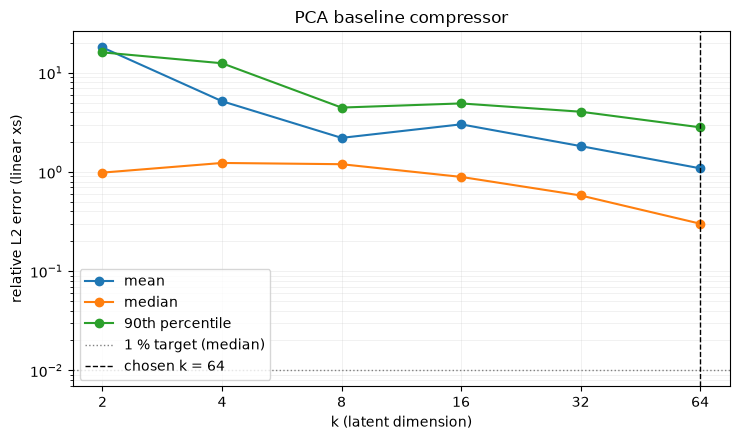

,k,mean_rel_err,median_rel_err,p90_rel_err,max_rel_err,explained_var
0,2,17.9764,0.9846,16.0436,3463.6020,0.8708
1,4,5.1650,1.2321,12.4662,256.8879,0.9320
2,8,2.2053,1.1971,4.4563,192.4590,0.9697
3,16,3.0195,0.8913,4.9055,345.8141,0.9863
4,32,1.8230,0.5794,4.0487,120.2270,0.9941
5,64,1.0883,0.3010,2.8186,26.9402,0.9978


In [3]:
err = pd.DataFrame(pca_err["rows"])
fig, ax = plt.subplots(figsize=(7.5, 4.5))
for col, lab in [("mean_rel_err", "mean"), ("median_rel_err", "median"), ("p90_rel_err", "90th percentile")]:
    ax.semilogy(err.k, err[col], marker="o", label=lab)
ax.axhline(0.01, color="gray", ls=":", lw=1, label="1 % target (median)")
ax.axvline(pca_err["chosen_k"], color="k", ls="--", lw=1, label=f"chosen k = {pca_err['chosen_k']}")
ax.set_xscale("log", base=2); ax.set_xticks(err.k, err.k)
ax.set(xlabel="k (latent dimension)", ylabel="relative L2 error (linear xs)", title="PCA baseline compressor")
ax.legend(); ax.grid(alpha=.3, which="both", lw=.4)
plt.tight_layout(); plt.show()
err.round(4)

## 3. Monte-Carlo k_inf: latent-space vs full grid-space sampling

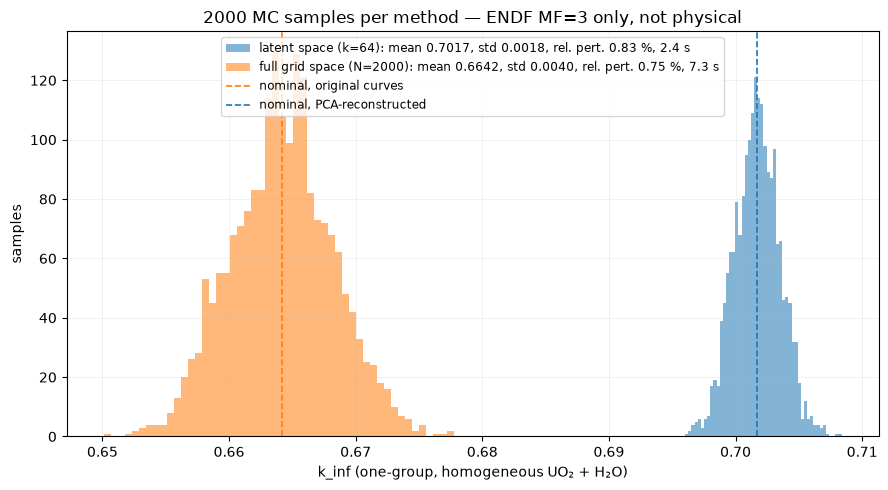

In [4]:
fig, ax = plt.subplots(figsize=(9, 5))
mc = uqs["mc"]
labels = {"latent": f"latent space (k={uqs['latent_k']})", "full": f"full grid space (N={grid['n']})"}
for i, m in enumerate(("latent", "full")):
    k = samples.loc[samples.method == m, "k_inf"]
    r = mc[m]
    ax.hist(k, bins=50, alpha=.55, color=f"C{i}",
            label=f"{labels[m]}: mean {r['mean']:.4f}, std {r['std']:.4f}, "
                  f"rel. pert. {100*r['rel_pert_rms_mean']:.2f} %, {r['seconds']:.1f} s")
ax.axvline(uqs["k_inf_nominal_original"], color="C1", ls="--", lw=1.2, label="nominal, original curves")
ax.axvline(uqs["k_inf_nominal_reconstructed"], color="C0", ls="--", lw=1.2, label="nominal, PCA-reconstructed")
ax.set(xlabel="k_inf (one-group, homogeneous UO₂ + H₂O)", ylabel="samples",
       title=f"{len(samples)//2} MC samples per method — ENDF MF=3 only, not physical")
ax.legend(fontsize=8.5, loc="upper center"); ax.grid(alpha=.3, lw=.4)
plt.tight_layout()
(OUT / "figures").mkdir(exist_ok=True)
fig.savefig(OUT / "figures" / "thin_e2e_kinf.png", dpi=150)
plt.show()

## Reading the results
- **Plumbing:** all four stages run end to end; outputs are Parquet/JSON and reproducible (seeded per MC batch).
- **Compression:** PCA in log10 space struggles with these curves. The sharp −10 → 0 cliffs at reaction thresholds and at the
  edge of the empty RRR are not linear-subspace friendly, so even k=64 leaves a large linear-space error. This is the
  motivation for the non-linear autoencoder (stage 2 replacement via the `Compressor` interface).
- **Propagation:** the compression error shows up directly as a bias between the two nominal k_inf lines.
  Latent-space MC samples only within the PCA subspace, so its spread is narrower than full-space MC at a
  similar per-point perturbation level. A better compressor should close both gaps.